# CNN-Based Image Classification Using Deep Learning

**Project type:** Multi-class image classification  
**Framework:** TensorFlow / Keras  
**Environment:** Kaggle Notebook (GPU-enabled session)  
**Dataset:** Intel Image Classification — natural scene images

---

## 1. Project Overview

### Problem statement
The goal is to build a Convolutional Neural Network (CNN) that takes a natural-scene image as input and predicts which of six categories it belongs to.

### Objectives
- Load and prepare labeled image data.
- Build and train a CNN for six-class classification.
- Evaluate the model using validation and test data.
- Visualize learning curves and compare predicted labels with actual labels.

### Class labels
`buildings`, `forest`, `glacier`, `mountain`, `sea`, and `street`.

> **Presentation tip:** Explain the workflow in this order: image → preprocessing → convolution and ReLU → pooling → flatten → dense layer → softmax probabilities → predicted class.

## 2. Imports and Dataset Setup

The dataset is already attached to this Kaggle notebook. The training folder contains **14,034 images**. We use an 80/20 split for training and validation, and keep the separate test folder for final evaluation.

- **Training:** 11,228 images (80% of the training folder)
- **Validation:** 2,806 images (20% of the training folder)
- **Testing:** 3,000 separate images
- **Image size:** 128 × 128 pixels
- **Batch size:** 32

The fixed random seed helps make the train/validation split reproducible.

In [7]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Load training images (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load validation images (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load testing images
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("All datasets loaded successfully!")

Found 14034 files belonging to 6 classes.
Using 11228 files for training.


I0000 00:00:1791806257.464757      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791806257.471837      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
All datasets loaded successfully!


## 3. Image Preprocessing: Normalization

Image pixels usually range from **0 to 255**. The `Rescaling(1./255)` layer maps them to the range **0 to 1**:

\[
 x_{normalized} = rac{x}{255}
\]

This puts pixel values on a smaller, consistent scale and helps neural-network training. The same transformation is applied to training, validation, and test images.

In [8]:
# Normalize pixel values from 0–255 to 0–1

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels)
)

print("Image normalization completed!")

Image normalization completed!


## 4. CNN Architecture

A CNN learns visual patterns automatically. Early convolution layers can learn simple patterns such as edges and textures; deeper layers can combine them into more complex patterns useful for distinguishing scenes.

### Architecture used

| Stage | Layer | Output dimensions | Purpose |
|---|---|---:|---|
| Input | RGB image | 128 × 128 × 3 | 3 color channels |
| 1 | Conv2D, 32 filters, 3×3, ReLU, same padding | 128 × 128 × 32 | Learn low-level features |
| 2 | Max Pooling, 2×2 | 64 × 64 × 32 | Downsample feature maps |
| 3 | Conv2D, 64 filters, 3×3, ReLU, same padding | 64 × 64 × 64 | Learn richer patterns |
| 4 | Max Pooling, 2×2 | 32 × 32 × 64 | Reduce spatial dimensions |
| 5 | Conv2D, 128 filters, 3×3, ReLU, same padding | 32 × 32 × 128 | Learn higher-level features |
| 6 | Max Pooling, 2×2 | 16 × 16 × 128 | Further downsampling |
| 7 | Flatten | 32,768 values | Convert feature maps to a vector |
| 8 | Dense, 128 units, ReLU | 128 | Combine extracted features |
| 9 | Dropout, 0.3 | 128 (during inference) | Regularization during training |
| Output | Dense, 6 units, Softmax | 6 probabilities | Score each scene class |

### Key concepts to explain
- **Filter/kernel:** A small learnable matrix that slides over an image/feature map to detect patterns. This model uses 3×3 filters in convolution layers.
- **Feature map:** The output produced by applying a filter to the input.
- **ReLU:** \(f(x)=\max(0,x)\), adding non-linearity.
- **Max pooling:** Keeps the maximum value in each 2×2 region, reducing width and height by half.
- **Flatten:** Changes a 3D block of feature maps into a 1D vector.
- **Dense layer:** Combines extracted features to make the final decision.
- **Softmax:** Converts output scores into class probabilities that sum to approximately 1.

### Dimension calculations
For convolution, the output size per spatial dimension is:

\[
N_{out}=\left\lfloorrac{N-F+2P}{S}ightfloor+1
\]

where \(N\) is input size, \(F\) is filter size, \(P\) is padding, and \(S\) is stride. With a 3×3 filter, stride 1, and `same` padding, width and height stay the same. A 2×2 max-pooling layer with stride 2 halves them.

After the last pooling layer: \(16	imes16	imes128=32,768\) values are flattened.


In [9]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Input layer
    layers.Input(shape=(128, 128, 3)),

    # Convolutional block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten feature maps
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Output layer: six classes
    layers.Dense(6, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,454 (16.36 MB)

 Trainable params: 4,288,454 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Model Compilation

Before training, we choose:

- **Optimizer — Adam:** Updates model weights to reduce loss.
- **Loss — Sparse categorical cross-entropy:** Suitable for multi-class classification when labels are integer class IDs.
- **Metric — Accuracy:** Fraction of predictions that match the correct label.

The output layer has six units because there are six classes.

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


## 6. Model Training

The model is trained for up to **8 epochs**. An epoch is one pass through the training data. **Early stopping** monitors validation loss and stops training if it fails to improve for two consecutive epochs. `restore_best_weights=True` restores the weights from the epoch with the lowest validation loss.

This helps reduce unnecessary training and can limit overfitting.

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stopping]
)

Epoch 1/8
 10/351 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.1937 - loss: 2.0227

I0000 00:00:1791806410.592871     163 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


351/351 ━━━━━━━━━━━━━━━━━━━━ 38s 92ms/step - accuracy: 0.6158 - loss: 0.9990 - val_accuracy: 0.6668 - val_loss: 0.9013
Epoch 2/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.7416 - loss: 0.7091 - val_accuracy: 0.7537 - val_loss: 0.6576
Epoch 3/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.8099 - loss: 0.5284 - val_accuracy: 0.8008 - val_loss: 0.5832
Epoch 4/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.8505 - loss: 0.4211 - val_accuracy: 0.7986 - val_loss: 0.5971
Epoch 5/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.8852 - loss: 0.3217 - val_accuracy: 0.7894 - val_loss: 0.6749


## 7. Training Curves

### Accuracy curve
Training accuracy measures performance on the training set; validation accuracy measures performance on the held-out validation set during training.

### Loss curve
Loss measures how far predictions are from the target labels. Lower is generally better. If training loss keeps decreasing while validation loss rises, that is a warning sign of **overfitting**.

In this run, training accuracy increased from about **61.58%** at epoch 1 to **88.52%** at epoch 5. Validation accuracy peaked around **80.08%** at epoch 3, while validation loss was lowest at about **0.5832** at epoch 3. The later gap suggests some overfitting, which is worth mentioning honestly in the presentation.

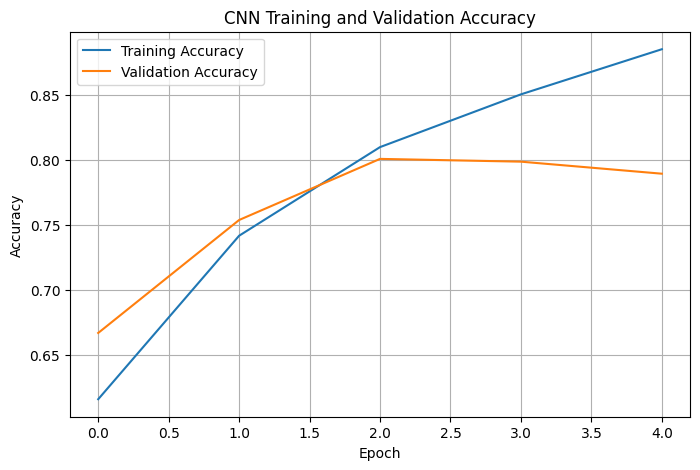

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

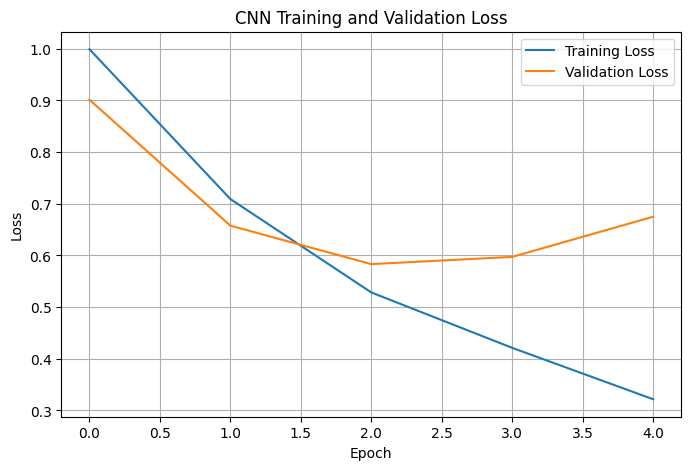

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## 8. Final Evaluation on the Test Set

The test set contains 3,000 images that were not used to update model weights during training. It gives an estimate of performance on unseen images.

**Recorded result from this run:**
- **Test accuracy:** 79.93%
- **Test loss:** 0.5975

Accuracy of 79.93% means the model correctly classified about 80 out of every 100 test images. It does not mean the model is perfect; the confusion between visually similar scenes is a useful limitation to discuss.

In [14]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.7993 - loss: 0.5975
Test Loss: 0.5975
Test Accuracy: 79.93%


## 9. Example Predictions

The next cell displays six test images with both the **predicted class** and the **actual class**. If the two labels match, that example was classified correctly. If they differ, it is an error the model made.

The confidence shown by a softmax model is the highest predicted class probability; it should not automatically be treated as a guarantee that the prediction is correct.

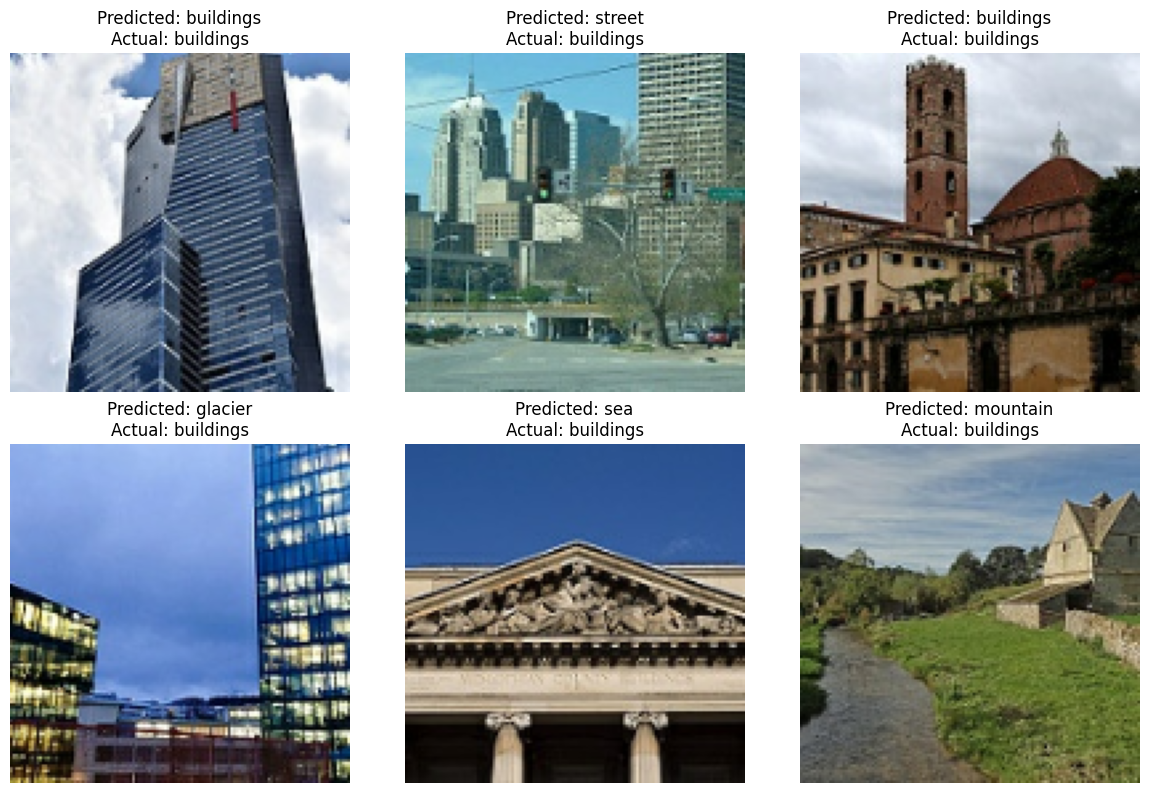

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Your dataset's six classes
class_names = ['buildings', 'forest', 'glacier',
               'mountain', 'sea', 'street']

# Get one batch of test images
for images, labels in test_ds.take(1):

    # Make predictions
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 8))

    for i in range(6):
        plt.subplot(2, 3, i + 1)

        # Find the class with the highest probability
        predicted_index = np.argmax(predictions[i])

        # Get the actual class
        actual_index = int(labels[i].numpy())

        # Display the image
        plt.imshow(images[i].numpy())

        predicted_class = class_names[predicted_index]
        actual_class = class_names[actual_index]

        # Show predicted and actual labels
        plt.title(
            f"Predicted: {predicted_class}\nActual: {actual_class}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## 10. Save the Trained Model

The model is saved in Kaggle's working directory as `cnn_scene_classifier.keras`. In Kaggle, files saved under `/kaggle/working/` can be downloaded from the Output/Files area after the notebook has run.

In [17]:
model.save('/kaggle/working/cnn_scene_classifier.keras')

print("CNN model saved successfully!")

CNN model saved successfully!


## 11. Conclusion and Discussion

### Conclusion
A CNN was developed to classify natural-scene images into six categories. The model uses three convolution/pooling blocks followed by a dense classifier and a six-unit softmax output. In this run, it achieved **79.93% test accuracy**.

### Limitations and possible improvements
- The learning curves suggest some overfitting after the third epoch.
- Try data augmentation, additional dropout or regularization, and careful tuning of learning rate and architecture.
- Inspect a confusion matrix to learn which scene categories are most often confused.
- Compare this baseline with transfer learning (for example, MobileNetV2) if time and compute resources permit.

### Questions you may be asked
1. **Why CNN instead of a regular fully connected network?** CNNs exploit local spatial patterns and share filter weights, making them well suited to images.
2. **Why normalize pixels?** To scale values from 0–255 to 0–1 for more stable optimization.
3. **Why use pooling?** It reduces spatial dimensions and computation while retaining strong activations.
4. **Why softmax?** The task has six mutually exclusive classes; softmax gives a score distribution across them.
5. **What does 79.93% test accuracy mean?** Roughly 80% of the 3,000 test images were classified correctly.
6. **What is overfitting in this run?** Training performance kept improving while validation performance stopped improving and validation loss rose.

---

**Presentation reminder:** Be ready to explain the idea behind each stage instead of only reading the code. Use the architecture table, learning curves, test accuracy, and example predictions as your main visual evidence.